# Object Orineted Programming: OOP's
- Object-Oriented Programming (OOP) is a programming model that organizes code around objects, which combine data (attributes) and functions (methods) that operate on that data, making code modular, reusable, and easier to manage by modeling real-world entities. 
- Key concepts include classes (blueprints for objects), objects (instances of classes), inheritance, encapsulation, abstraction, and polymorphism, which help create flexible and scalable applications. 

## 1. Encapsulation (The "Medicine Capsule")
Definition: Bundling data (variables) and methods (functions) into a single unit (a class) and restricting access to the inner workings.

Memory Tip: Think of a Medicine Capsule. You take the pill to get better, but you don't need to see or touch the powder inside for it to work.

In [1]:
class BankAccount:
    def __init__(self, balance: float):
        self.__balance = balance  # Private variable (The powder inside)

    def deposit(self, amount: float):
        if amount > 0:
            self.__balance += amount
            print(f"Deposited {amount}")

    def get_balance(self):
        return f"Accessing vault... Balance: {self.__balance}"

# You can't touch the balance directly (e.g., acc.__balance = 999999)
# You MUST use the methods provided.

## 2. Abstraction (The "Car Dashboard")
Definition: Hiding complex implementation details and only showing the necessary features to the user.

Memory Tip: Think of a Car Dashboard. You press the "Start" button (the interface). You don't need to know how the spark plugs, fuel pump, and pistons work together to start the engine.

In [2]:
from abc import ABC, abstractmethod

class RemoteControl(ABC):
    @abstractmethod
    def press_power_button(self):
        pass

class TVRemote(RemoteControl):
    def press_power_button(self):
        print("Connecting to satellite... Warming up pixels... TV ON!")

# The user just knows they need to 'press_power_button'
my_remote = TVRemote()
my_remote.press_power_button()


Connecting to satellite... Warming up pixels... TV ON!


## 3. Inheritance (The "Family Tree")
Definition: A way to create a new class using details from an existing class. The "Child" class inherits attributes and methods from the "Parent" class.

Memory Tip: Think of DNA. You inherit your eye color from your parents, but you might also have your own unique skills, like playing the guitar.

In [4]:
class Animal:
    def breathe(self):
        print("Inhale... Exhale...")

class Dog(Animal):  # Dog inherits from Animal
    def bark(self):
        print("Meow i say")

# The dog can breathe (from parent) AND bark (its own skill)
my_dog = Dog()
my_dog.breathe() 
my_dog.bark()

Inhale... Exhale...
Meow i say


## 4. Polymorphism (The "Swiss Army Knife")
Definition: The ability of different classes to be treated as instances of the same general class through the same interface. "Many shapes."

Memory Tip: Think of the word "Cut."

To a hairdresser, "cut" means use scissors.

To a director, "cut" means stop filming.

To a chef, "cut" means use a knife. The command is the same, but the action depends on who is doing it.

In [5]:
class Bird:
    def move(self):
        print("Flying high!")

class Penguin(Bird):
    def move(self):  # Overriding the parent method
        print("Waddling on ice!")

def make_it_move(animal_type):
    animal_type.move()

# Same function name, different results!
make_it_move(Bird())    # Flying high!
make_it_move(Penguin()) # Waddling on ice!

Flying high!
Waddling on ice!


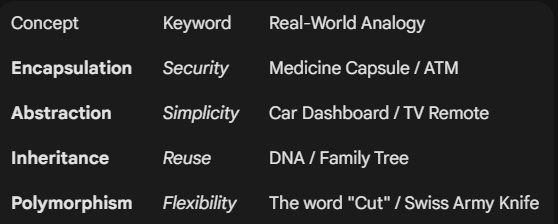

# 🐍 Python OOP Master Cheat Sheet
> **Goal:** Build robust, scalable, and secure code using the four pillars of Object-Oriented Programming.

---

## 🏗️ 1. The Basics: Classes & Objects
* **Class:** The blueprint (e.g., a "Car" design).
* **Object:** The actual house built from the blueprint (e.g., your "Red Tesla").
* **`self`:** The "Sticky Note" that keeps track of which specific object we are talking about.

```python
class Dog:
    def __init__(self, name):
        self.name = name # Instance Attribute
```
![Screenshot 2026-02-10 220921.png](<attachment:Screenshot 2026-02-10 220921.png>) 

![Screenshot 2026-02-10 220910.png](<attachment:Screenshot 2026-02-10 220910.png>) 

![Screenshot 2026-02-10 220848.png](<attachment:Screenshot 2026-02-10 220848.png>)
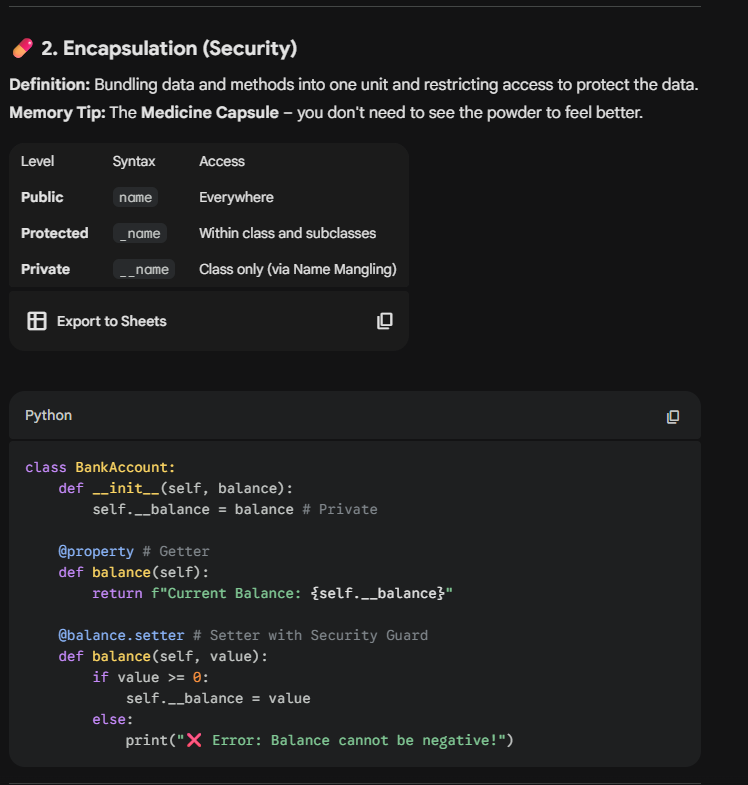
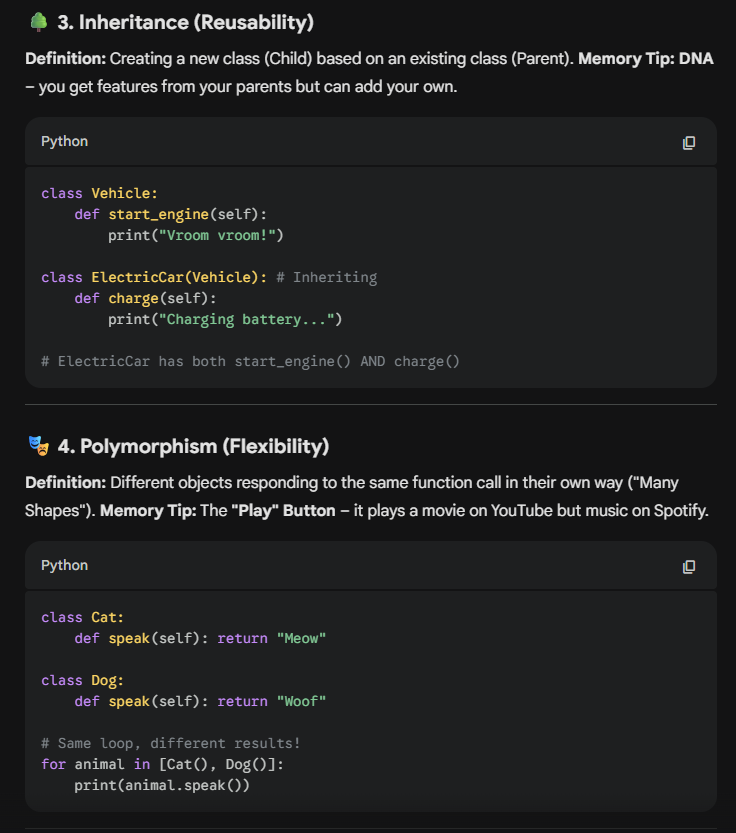
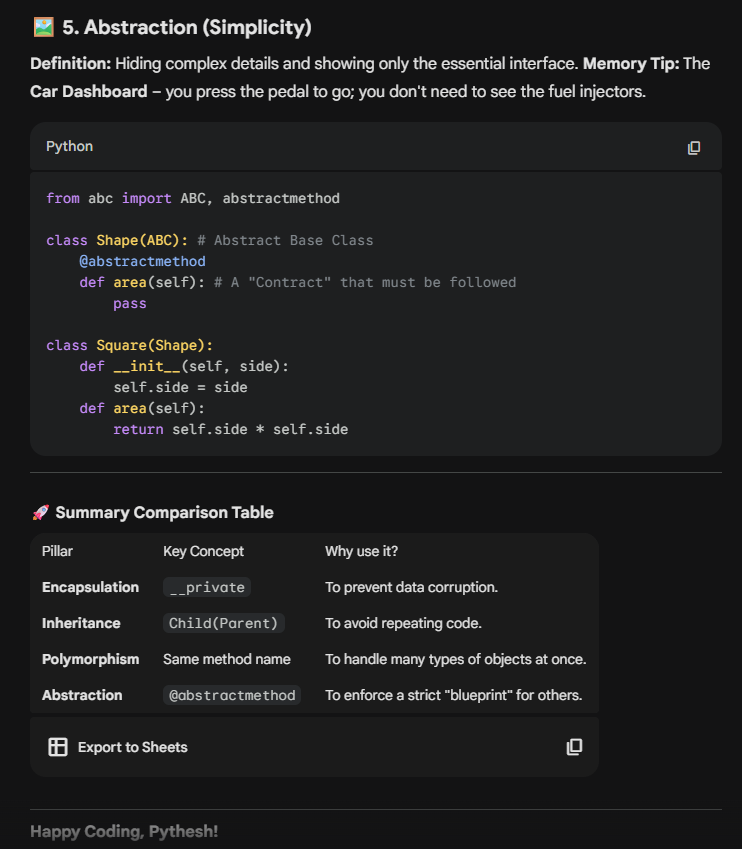

In [4]:
from abc import ABC, abstractmethod

# 1. ABSTRACTION: The "Media" Blueprint
class Media(ABC):
    def __init__(self, title, media_id):
        self.title = title
        self.media_id = media_id
        self.__is_available = True  # 2. ENCAPSULATION: Private status

    @property
    def is_available(self):
        return self.__is_available

    @is_available.setter
    def is_available(self, status):
        self.__is_available = status

    @abstractmethod
    def display_info(self):
        """Must be implemented by Book, Magazine, etc."""
        pass

# 3. INHERITANCE: Specific Media Types
class Book(Media):
    def __init__(self, title, media_id, author):
        super().__init__(title, media_id)
        self.author = author

    def display_info(self): # 4. POLYMORPHISM
        status = "✅ Available" if self.is_available else "❌ Out on Loan"
        print(f"[BOOK] {self.title} by {self.author} | ID: {self.media_id} | {status}")

class Magazine(Media):
    def __init__(self, title, media_id, issue_no):
        super().__init__(title, media_id)
        self.issue_no = issue_no

    def display_info(self): # 4. POLYMORPHISM
        status = "✅ Available" if self.is_available else "❌ Out on Loan"
        print(f"[MAG] {self.title} (Issue #{self.issue_no}) | ID: {self.media_id} | {status}")

# 🏛️ The Library Manager Class
class Library:
    def __init__(self):
        self.inventory = []

    def add_item(self, item: Media):
        self.inventory.append(item)
        print(f"Added: {item.title}")

    def lend_item(self, media_id):
        for item in self.inventory:
            if item.media_id == media_id:
                if item.is_available:
                    item.is_available = False # Using the Setter
                    print(f"Success: You borrowed '{item.title}'")
                else:
                    print(f"Error: '{item.title}' is already borrowed.")
                return
        print("Error: Item ID not found.")
    
    # --- NEW: Return Logic ---
    def return_item(self, media_id):
        for item in self.inventory:
            if item.media_id == media_id:
                if not item.is_available:
                    item.is_available = True # <--- Making it available again
                    print(f"✅ Returned: '{item.title}'. Thank you!")
                else:
                    print(f"⚠️ Note: '{item.title}' was already in the library.")
                return
        print("❌ Error: Item ID not found.")
    # --- NEW: Search by Author ---
    def search_by_author(self, author_name):
        print(f"\n🔍 Searching for books by: {author_name}")
        results = []
        
        for item in self.inventory:
            # Check if the item is a Book (since Magazines don't have authors)
            if isinstance(item, Book): 
                if item.author.lower() == author_name.lower():
                    results.append(item)
        
        if results:
            for r in results:
                r.display_info()
            print("---------------------------------\n")
        else:
            print(f"No books found by {author_name}.")

    def show_all_items(self):
        print("\n--- Current Inventory ---")
        for item in self.inventory:
            item.display_info()

# --- TESTING THE NEW FEATURES ---
my_lib = Library()
my_lib.add_item(Book("Python Mastery", "B001", "Pythesh"))
my_lib.add_item(Book("AI Basics", "B002", "Pythesh"))
my_lib.add_item(Magazine("Tech Weekly", "M502", 12))

# 1. Borrow and Return
my_lib.lend_item("B001")
my_lib.return_item("B001")

# 2. Search
my_lib.search_by_author("Pythesh")
# --- EXECUTION ---
my_lib = Library()

# Add items
my_lib.add_item(Book("Python Mastery", "B001", "Pythesh"))
my_lib.add_item(Magazine("Tech Weekly", "M502", 12))

# Show inventory
my_lib.show_all_items()

# Borrow an item
my_lib.lend_item("B001")

# Show updated inventory
my_lib.show_all_items()

Added: Python Mastery
Added: AI Basics
Added: Tech Weekly
Success: You borrowed 'Python Mastery'
✅ Returned: 'Python Mastery'. Thank you!

🔍 Searching for books by: Pythesh
[BOOK] Python Mastery by Pythesh | ID: B001 | ✅ Available
[BOOK] AI Basics by Pythesh | ID: B002 | ✅ Available
---------------------------------

Added: Python Mastery
Added: Tech Weekly

--- Current Inventory ---
[BOOK] Python Mastery by Pythesh | ID: B001 | ✅ Available
[MAG] Tech Weekly (Issue #12) | ID: M502 | ✅ Available
Success: You borrowed 'Python Mastery'

--- Current Inventory ---
[BOOK] Python Mastery by Pythesh | ID: B001 | ❌ Out on Loan
[MAG] Tech Weekly (Issue #12) | ID: M502 | ✅ Available
